# Does Corporate Leverage Explain the Cross-Section of Stock Returns?
**A market-leverage factor (LEV), CRSP and Compustat, January 1974 - December 2018**

Run top to bottom (about 2-3 minutes). Inputs in this folder: `compustat.csv.gz`, `crsp_monthly.csv.gz`, `04_Fama_French_Monthly_Factors.csv`. No internet access is needed.

## 1. Research question, economic rationale and audience

**Question.** Does corporate leverage help explain the cross-section of stock returns beyond the market, size (SMB), value (HML) and momentum (UMD)?

**Proposed factor.** **LEV = return of high-leverage stocks minus return of low-leverage stocks**, where leverage = debt / (debt + market equity). This ranks stocks exactly as debt / market capitalization does. LEV is a candidate additional factor, not a renamed SMB, HML or UMD.

**Why leverage might earn a risk premium (bad times).** In the multifactor framework, an asset earns a premium for doing badly in the states of the world investors dislike most ("bad times": recessions, credit crunches, market crashes), because it cannot be used to insure against them. Highly leveraged firms have large fixed obligations, so falling cash flows, tighter credit or higher interest rates push them toward distress and refinancing problems, and their equity should lose more in bad times. Investors would then demand a higher expected return for holding them.

**Testable predictions (the hypothesis can fail).**
1. LEV earns a positive average return.
2. That return is not explained by Mkt-RF, SMB, HML and UMD (a zero alpha would mean no new premium).
3. LEV does badly in bad times (recessions, market declines), which is the risk that would justify the premium.
4. Adding LEV improves the explanation of returns on test assets, especially assets that were *not* sorted on leverage.

**Alternative explanations.** (a) *Overlap with value:* market equity is in the denominator of both leverage and book-to-market, so low-priced stocks look both highly leveraged and "value"; LEV may just be HML. (b) *Behavioral:* investors may misprice distress or extrapolate past performance. These are separated in Sections 5, 7 and 10.

**Intended audience.** Quantitative equity managers deciding whether to add a leverage tilt to a portfolio that already holds value and momentum exposures. Pension funds and other institutions evaluating a leverage-based factor product have the same question: is there a premium that the factors they already hold do not provide, and does it survive costs?

**Roadmap.** Sections 2-3 data, cleaning and factor construction; 4-5 benchmark factors and regressions; 6 sensitivity; 7-8 bad times and charts; 9 results; 10 rational vs behavioral; 11 market efficiency; 12 conclusion and limitations; 13 requirements checklist.

## 2. Data, sample selection and cleaning
| Source | Used for |
|---|---|
| Compustat quarterly (WRDS) | short-term debt `dlcq`, long-term debt `dlttq` (USD millions), total assets `atq`, earnings-announcement date `rdq` |
| CRSP monthly (WRDS) | total return `MthRet`, price, shares outstanding, exchange and security-type flags |
| CCM link table (in the Compustat file) | maps each stock (PERMNO) to its company (GVKEY) with valid dates |
| Fama-French / Carhart factors (`04_...csv`) | Mkt-RF, SMB, HML, UMD, RF in decimals; identical to the Ken French library (checked) |

**Returns.** `MthRet` is CRSP's **total** monthly holding-period return: it includes dividends and is adjusted for splits and other distributions, so no manual price adjustment (`CFACPR`) is needed. `MthRetx` (excludes dividends) and the raw price are not used for returns. Frequency: monthly. Market equity = |price| x shares / 1000 ($ millions; CRSP prices can be negative to flag bid/ask averages).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from math import erfc, sqrt

**What this does:** imports the libraries. Regressions are hand-written in numpy (`ols` below); they were verified against `statsmodels` HAC regressions and agree to 1e-14.

### 2a. Compustat: quarterly debt

In [2]:
raw = pd.read_csv("compustat.csv.gz", dtype={"GVKEY": str, "cusip": str, "sic": str},
                  parse_dates=["datadate", "rdq", "LINKDT"])
raw.columns = raw.columns.str.lower()
raw["linkenddt"] = pd.to_datetime(raw["linkenddt"].replace("E", pd.NaT), errors="coerce")

log = [("raw rows (one per company-quarter-link)", len(raw))]

fund_cols = ["gvkey", "datadate", "rdq", "sic", "atq", "dlcq", "dlttq"]
fund = raw[fund_cols].drop_duplicates()
log.append(("remove repeats caused by multiple links", len(fund)))

fund = fund.drop_duplicates(["gvkey", "datadate"], keep="first")
log.append(("remove duplicate company-quarters", len(fund)))

fund = fund[fund["datadate"] <= "2025-12-31"]
log.append(("trim to 2025", len(fund)))

sic = pd.to_numeric(fund["sic"], errors="coerce")
fund = fund[~sic.between(6000, 6999)]
log.append(("drop financials (SIC 6000-6999)", len(fund)))

fund = fund[fund[["dlcq", "dlttq"]].notna().any(axis=1)]
log.append(("has debt data (missing values)", len(fund)))

# total debt = short-term + long-term (a missing piece counts as 0)
fund["debt"] = fund["dlcq"].fillna(0) + fund["dlttq"].fillna(0)
fund = fund[fund["debt"] >= 0]
log.append(("non-negative debt", len(fund)))

comp_log = pd.DataFrame(log, columns=["step", "n_obs"]); comp_log["dropped"] = -comp_log["n_obs"].diff()
print(comp_log)

                                      step    n_obs   dropped
0  raw rows (one per company-quarter-link)  1215146       NaN
1  remove repeats caused by multiple links  1202916   12230.0
2        remove duplicate company-quarters  1202753     163.0
3                             trim to 2025  1191721   11032.0
4          drop financials (SIC 6000-6999)   895530  296191.0
5           has debt data (missing values)   862299   33231.0
6                        non-negative debt   862296       3.0


**What this does:** loads the raw Compustat file (one row per company x quarter x CRSP link) and builds one clean row per company-quarter with total debt.
- Drops repeats caused by multiple links, then duplicate company-quarters (duplicates).
- Drops financial firms (SIC 6000-6999): their debt is part of their business, so leverage means something different.
- Total debt = `dlcq` + `dlttq`. A firm must report at least one (missing values); a missing piece counts as 0.
- The printed table is the "observations affected by each step" log.

In [3]:
# link table: which PERMNOs belong to which company (needed to sum market equity across share classes)
links = raw[["gvkey", "lpermno", "linkprim", "linktype", "linkdt", "linkenddt"]].drop_duplicates()
links["linkenddt"] = links["linkenddt"].fillna(pd.Timestamp("2099-12-31"))
links = links[links["gvkey"].isin(fund["gvkey"].unique())]

links["lpermno"].astype(int).drop_duplicates().sort_values().to_csv("permnos.txt", index=False, header=False)
print(links["gvkey"].nunique(), "companies,", links["lpermno"].nunique(), "PERMNOs")

21120 companies, 21639 PERMNOs


**What this does:** builds the **link table** (which stock belongs to which company, over what dates) and saves the PERMNO list used to pull CRSP. A company can have several share classes, and we measure leverage at the *company* level.

> **Data note:** the share of firms with zero reported debt falls from ~19% to ~6% in 2019Q1. The firms that jump are mostly retailers with large store leases (Ulta, American Eagle, Urban Outfitters, Five Below), which points to the 2019 lease-accounting change (ASC 842) adding lease liabilities to Compustat debt, not to missing data. The series is therefore not comparable across 2019, so the sample ends in 2018.

### 2b. CRSP: monthly total returns

In [4]:
crsp = pd.read_csv("crsp_monthly.csv.gz", dtype={"HdrCUSIP": str})
crsp.columns = crsp.columns.str.lower()
crsp["mthcaldt"] = pd.to_datetime(crsp["mthcaldt"])

log = [("raw CRSP rows", len(crsp))]

crsp = crsp[(crsp["securitytype"] == "EQTY") & (crsp["securitysubtype"] == "COM") &
            (crsp["sharetype"] == "NS") & (crsp["usincflg"] == "Y")]
log.append(("US common stock", len(crsp)))

crsp = crsp[crsp["primaryexch"].isin(["N", "A", "Q"])]
log.append(("NYSE/AMEX/NASDAQ", len(crsp)))

crsp = crsp[(crsp["mthcaldt"] >= "1973-01-01") & (crsp["mthcaldt"] <= "2025-12-31")]
log.append(("1973-2025", len(crsp)))

crsp["me"] = crsp["mthprc"].abs() * crsp["shrout"] / 1000
crsp = crsp[crsp["me"] > 0]
log.append(("positive market equity (drops missing prices)", len(crsp)))

# every duplicate permno-month is an exact duplicate row
crsp = crsp.drop_duplicates().sort_values(["permno", "mthcaldt"])
assert not crsp.duplicated(["permno", "mthcaldt"]).any()
log.append(("remove exact duplicate rows (duplicates)", len(crsp)))

crsp_log = pd.DataFrame(log, columns=["step", "n_obs"]); crsp_log["dropped"] = -crsp_log["n_obs"].diff()
print(crsp_log)
print("missing MthRet (missing values):", crsp["mthret"].isna().sum())

                                            step    n_obs   dropped
0                                  raw CRSP rows  2961391       NaN
1                                US common stock  2569656  391735.0
2                               NYSE/AMEX/NASDAQ  2518587   51069.0
3                                      1973-2025  2518587      -0.0
4  positive market equity (drops missing prices)  2508393   10194.0
5       remove exact duplicate rows (duplicates)  2500417    7976.0
missing MthRet (missing values): 869


**What this does:** loads and cleans CRSP monthly stock data.
- Keeps US common stock listed on NYSE/AMEX/NASDAQ, 1973-2025.
- Computes market equity and drops observations without a positive market value.
- Removes exact duplicate rows (every duplicated permno-month was an identical row) and asserts none remain.
- Counts the missing returns; these observations drop out later because the return to be explained must exist.

### 2c. Merge: company market equity, leverage and timing
Fundamentals are matched to month t only after their public date (`rdq`, else `datadate` + 3 months), so leverage at month t uses no future information. The stock's return in month t+1 is the return we explain.

In [5]:
# stock -> company link valid in that month; company ME sums all share classes
m = crsp[["permno", "mthcaldt", "me"]].merge(
        links[["gvkey", "lpermno", "linkprim", "linkdt", "linkenddt"]],
        left_on="permno", right_on="lpermno", how="inner")
m = m[(m["mthcaldt"] >= m["linkdt"]) & (m["mthcaldt"] <= m["linkenddt"])]

# if a stock maps to several companies in a month, keep the best link: P (primary) > C > J > N
m["prio"] = m["linkprim"].map({"P": 0, "C": 1, "J": 2, "N": 3}).fillna(4)
print(m.duplicated(["permno", "mthcaldt"]).sum(), "stock-months had more than one valid link")
m = m.sort_values(["permno", "mthcaldt", "prio"]).drop_duplicates(["permno", "mthcaldt"])

firm_me = (m.groupby(["gvkey", "mthcaldt"], as_index=False)["me"].sum()
             .rename(columns={"me": "firm_me"}).sort_values("mthcaldt"))
print(len(m), "stock-months matched;", len(firm_me), "company-months")

fund["avail"] = fund["rdq"].where(fund["rdq"] >= fund["datadate"])
fund["avail"] = fund["avail"].fillna(fund["datadate"] + pd.DateOffset(months=3))
fund = fund.sort_values("avail")

panel = pd.merge_asof(firm_me, fund[["gvkey", "avail", "datadate", "debt", "atq"]],
                      left_on="mthcaldt", right_on="avail", by="gvkey",
                      direction="backward", tolerance=pd.Timedelta(days=365))
panel = panel.dropna(subset=["debt"])
panel["mkt_lev"]  = panel["debt"] / (panel["debt"] + panel["firm_me"])
panel["book_lev"] = panel["debt"] / panel["atq"].where(panel["atq"] > 0)     # for the sensitivity test
print(len(panel), "company-months with leverage")
print(panel[["mkt_lev", "book_lev"]].describe(percentiles=[.01, .5, .99]).round(3))

0 stock-months had more than one valid link
2468294 stock-months matched; 2442175 company-months
2264320 company-months with leverage
           mkt_lev     book_lev
count  2264320.000  2222492.000
mean         0.249        0.249
std          0.246        1.063
min          0.000        0.000
1%           0.000        0.000
50%          0.177        0.213
99%          0.906        0.955
max          1.000      855.111


**What this does:** turns the debt data into a monthly **market leverage** measure per company.
1. Attaches each stock to its company using only links valid in that month (best link P > C > J > N), then sums market equity across all share classes (`firm_me`).
2. Works out when each quarter became public: the announcement date `rdq`, else quarter-end + 3 months. This prevents look-ahead bias.
3. `merge_asof` gives each company-month the latest debt figure already public (at most 365 days old).
4. `mkt_lev = debt / (debt + market equity)`, a monotonic transformation of debt / market cap (it ranks stocks identically). `book_lev = debt / total assets` is kept for the sensitivity test.

In [6]:
# next month's return, taken from CRSP itself (only if the next row is the next calendar month)
r = crsp[["permno", "mthcaldt", "mthret"]].copy()
r["ym"] = r["mthcaldt"].dt.to_period("M")
r = r.sort_values(["permno", "ym"])
r["ret_next"] = r.groupby("permno")["mthret"].shift(-1)
r.loc[r.groupby("permno")["ym"].shift(-1) != r["ym"] + 1, "ret_next"] = np.nan

# stock-month panel: each PERMNO gets its company's leverage and next month's return
stock = (m[["permno", "mthcaldt", "gvkey", "me"]]
         .merge(panel[["gvkey", "mthcaldt", "mkt_lev", "book_lev"]], on=["gvkey", "mthcaldt"], how="inner")
         .merge(r[["permno", "mthcaldt", "ret_next"]], on=["permno", "mthcaldt"], how="left"))
stock["ret_month"] = stock["mthcaldt"].dt.to_period("M") + 1

log = [("stock-months with leverage", len(stock))]
stock = stock[stock["ret_next"].notna()]
log.append(("has next-month return (missing values)", len(stock)))
stock = stock[(stock["ret_month"] >= "1974-01") & (stock["ret_month"] <= "2018-12")]
log.append(("returns Jan 1974 - Dec 2018", len(stock)))

stock_log = pd.DataFrame(log, columns=["step", "n_obs"]); stock_log["dropped"] = -stock_log["n_obs"].diff()
print(stock_log)
stock.to_csv("stock_timed.csv", index=False)

                                     step    n_obs   dropped
0              stock-months with leverage  2290286       NaN
1  has next-month return (missing values)  2271089   19197.0
2             returns Jan 1974 - Dec 2018  2006414  264675.0


**What this does:** builds the final stock-month dataset.
- Each row is a stock with its company's leverage at the end of month *t* and its **next month's return** `ret_next` (month t+1). Sorting on information known at t and earning the t+1 return makes the test forward-looking.
- `ret_next` is only kept if the next row really is the next calendar month (no gaps).
- Keeps return months Jan 1974 - Dec 2018 and saves `stock_timed.csv` (regenerated on every run, not committed).

## 3. Winsorizing, audit and factor construction
**Winsorizing.** Within each month, next-month returns and the sorting characteristic (market leverage) are clipped at the **1st and 99th percentiles**; book leverage (used only in a sensitivity test) is clipped at the 99th percentile because it has extreme values (maximum 855). Market leverage lives in [0,1] and only its rank matters, so clipping it cannot change any portfolio assignment; it is clipped anyway so the procedure is the same for every variable, and the number of changed values is reported.

In [7]:
st = pd.read_csv("stock_timed.csv", usecols=["permno","gvkey","ret_month","me","mkt_lev","book_lev","ret_next"])
st["ret_month"] = pd.PeriodIndex(st["ret_month"], freq="M")

def winsorize(df, col, lo=.01, hi=.99):
    g = df.groupby("ret_month")[col]
    a, b = g.transform(lambda s: s.quantile(lo)), g.transform(lambda s: s.quantile(hi))
    clipped = df[col].clip(a, b)
    print(f"{col}: {(clipped != df[col]).sum():,} obs changed ({lo:.0%}/{hi:.0%} by month)")
    return clipped

st["ret_w"]  = winsorize(st, "ret_next")
st["lev_w"]  = winsorize(st, "mkt_lev")           # sorting characteristic
st["book_w"] = winsorize(st, "book_lev", 0, .99)

ret_next: 40,289 obs changed (1%/99% by month)
mkt_lev: 20,335 obs changed (1%/99% by month)
book_lev: 54,340 obs changed (0%/99% by month)


**What this does:** loads the stock-month panel and winsorizes returns and the sorting characteristic by month, printing how many observations each cut-off changes.

In [8]:
audit = pd.Series({
    "Compustat rows: raw -> cleaned": f"{comp_log.n_obs.iloc[0]:,} -> {comp_log.n_obs.iloc[-1]:,}",
    "CRSP rows: raw -> cleaned": f"{crsp_log.n_obs.iloc[0]:,} -> {crsp_log.n_obs.iloc[-1]:,}",
    "Exact duplicate CRSP rows removed": f"{int(crsp_log.dropped.iloc[-1]):,}",
    "Stock-months dropped: no next-month return": f"{int(stock_log.dropped.iloc[1]):,}",
    "Analysis sample (stock-months)": f"{len(st):,}",
    "Distinct stocks / months": f"{st.permno.nunique():,} / {st.ret_month.nunique()}",
    "Duplicate stock-months remaining": int(st.duplicated(["permno", "ret_month"]).sum()),
    "Missing returns / leverage remaining": f"{int(st.ret_next.isna().sum())} / {int(st.mkt_lev.isna().sum())}",
    "Returns changed by 1/99 winsorizing": f"{int((st.ret_w != st.ret_next).sum()):,}",
    "Leverage changed by 1/99 winsorizing": f"{int((st.lev_w != st.mkt_lev).sum()):,}"}, name="count")
audit.to_frame()

,count
Compustat rows: raw -> cleaned,"1,215,146 -> 862,296"
CRSP rows: raw -> cleaned,"2,961,391 -> 2,500,417"
Exact duplicate CRSP rows removed,"7,976"
Stock-months dropped: no next-month return,"19,197"
Analysis sample (stock-months),"2,006,414"
Distinct stocks / months,"16,801 / 540"
Duplicate stock-months remaining,0
Missing returns / leverage remaining,0 / 0
Returns changed by 1/99 winsorizing,"40,289"
Leverage changed by 1/99 winsorizing,"20,335"


**What this does:** one summary of the cleaning: how many observations each stage removed or changed (requirement 4), and confirmation that no duplicates or missing values remain in the analysis sample.

In [9]:
def assign(df, col, cuts):
    """Bucket 0..k each month by breakpoints on `col` (cuts e.g. [.3,.7])."""
    bp = df.groupby("ret_month")[col].quantile(cuts).unstack()
    bp.columns = range(len(cuts))
    x = df[["ret_month", col]].join(bp, on="ret_month")
    return sum((x[col] > x[i]).astype(int) for i in bp.columns)

def port_ret(df, by, weight="vw", ret="ret_w"):
    df = df.assign(w=df["me"] if weight == "vw" else 1.0)
    df["wr"] = df["w"] * df[ret]
    g = df.groupby(["ret_month"] + by)[["wr", "w"]].sum()
    return (g["wr"] / g["w"]).unstack(by)

def lev_legs(df, col="lev_w", cuts=(.3,.7), weight="vw", ret="ret_w"):
    """Low-leverage leg, high-leverage leg and LEV = high - low."""
    df = df.dropna(subset=[col])                    # stocks with no characteristic must not land in the low bucket
    df = df.assign(b=assign(df, col, list(cuts)))
    p = port_ret(df, ["b"], weight, ret)
    out = pd.DataFrame({"low": p[0], "high": p[len(cuts)]})
    out["LEV"] = out["high"] - out["low"]
    return out

def lev_factor(df, **kw):
    return lev_legs(df, **kw)["LEV"]

**What this does:** the building blocks, reused for every variant of the factor.
- `assign`: each month, finds the leverage breakpoints (e.g. 30th/70th percentile) and labels every stock 0 (low) to k (high).
- `port_ret`: monthly portfolio return, value-weighted by market equity (or equal-weighted).
- `lev_legs` / `lev_factor`: the two legs and the factor, **LEV = high-leverage return minus low-leverage return**, a zero-cost long-short portfolio. Value-weighted 30/70 is the baseline (large firms are not swamped by micro-caps); equal weights and other cut-offs are sensitivity tests.

## 4. Benchmark factors

In [10]:
ff = pd.read_csv("04_Fama_French_Monthly_Factors.csv", parse_dates=["date"])
ff.index = ff["date"].dt.to_period("M")
ff = ff.rename(columns={"Mkt_RF": "Mkt-RF", "Mom": "UMD"})[["Mkt-RF","SMB","HML","UMD","RF"]].loc["1974-01":"2018-12"]
assert len(ff) == 540 and ff.notna().all().all()
print(ff.describe().round(4).loc[["count","mean","std"]])

         Mkt-RF       SMB       HML      UMD        RF
count  540.0000  540.0000  540.0000  540.000  540.0000
mean     0.0059    0.0021    0.0031    0.006    0.0038
std      0.0450    0.0300    0.0288    0.043    0.0029


**What this does:** loads the monthly market excess return (`Mkt-RF`), size (`SMB`), value (`HML`), momentum (`UMD`) and risk-free rate (`RF`), in decimals, for the sample months. The file was supplied by a teammate and matches the Ken French data library (maximum difference about 1e-16 over these months), which lets the notebook run without internet access.

## 5. Regressions (OLS, Newey-West t-statistics with 6 lags)

In [11]:
def ols(y, X, lags=6):
    """OLS with Newey-West (Bartlett, `lags`) standard errors. Returns coefficients, t, p, R2, adjusted R2."""
    d = pd.concat([y, X], axis=1).dropna()
    yy, XX = d.iloc[:, 0].values, np.column_stack([np.ones(len(d)), d.iloc[:, 1:].values])
    n, k = XX.shape
    b = np.linalg.solve(XX.T @ XX, XX.T @ yy)
    e = yy - XX @ b
    S = (XX * e[:, None]).T @ (XX * e[:, None])
    for l in range(1, lags + 1):
        G = (XX[l:] * e[l:, None]).T @ (XX[:-l] * e[:-l, None])
        S += (1 - l / (lags + 1)) * (G + G.T)
    A = np.linalg.inv(XX.T @ XX)
    t = b / np.sqrt(np.diag(A @ S @ A))
    names = ["alpha"] + list(X.columns)
    r2 = 1 - e.var() / yy.var()
    return pd.Series({**dict(zip(names, b)), **{f"t_{n_}": v for n_, v in zip(names, t)},
                      **{f"p_{n_}": erfc(abs(v) / sqrt(2)) for n_, v in zip(names, t)},
                      "R2": r2, "adjR2": 1 - (1 - r2) * (n - 1) / (n - k), "N": n})

**What this does:** a hand-written OLS regression returning the intercept (alpha), coefficients, t-stats, p-values, R-squared and adjusted R-squared. The t-stats use **Newey-West standard errors (6 lags)**, which correct for autocorrelation and changing volatility in monthly returns. It was verified against `statsmodels` (`cov_type="HAC"`, 6 lags) and agrees to 1e-14.

### 5a. Is there a premium, and is LEV already explained by known factors?
Expected returns cannot be observed, so the premium is estimated as the **average realized monthly LEV return** over the 540 months and tested against zero with a Newey-West t-statistic.

In [12]:
legs = lev_legs(st)
lev = legs["LEV"]
d = ff.join(lev, how="inner")
print(f"LEV: mean {lev.mean()*100:.2f}%/mo, t = {ols(lev, pd.DataFrame(index=lev.index))['t_alpha']:.2f}")
print(f"     low-leverage leg {legs.low.mean()*100:.2f}%/mo, high-leverage leg {legs.high.mean()*100:.2f}%/mo")

print("\nIs LEV spanned by existing factors? (LEV regressed on each benchmark)")
for mname, f in [("CAPM", ["Mkt-RF"]), ("FF3", ["Mkt-RF","SMB","HML"]), ("FF3+UMD", ["Mkt-RF","SMB","HML","UMD"])]:
    r = ols(d["LEV"], d[f]); print(f"  {mname:8s} alpha {r['alpha']*100:5.2f}%  t {r['t_alpha']:5.2f}  R2 {r['R2']:.2f}")
r = ols(d["LEV"], d[["Mkt-RF","SMB","HML","UMD"]])
print("\nFF3+UMD loadings (t):", ", ".join(f"{k} {r[k]:.2f} ({r['t_'+k]:.1f})" for k in ["Mkt-RF","SMB","HML","UMD"]))
print(f"LEV-HML correlation {d.LEV.corr(d.HML):.2f}; R2 of LEV on HML alone {ols(d.LEV, d[['HML']])['R2']:.2f}")

LEV: mean 0.08%/mo, t = 0.37
     low-leverage leg 0.97%/mo, high-leverage leg 1.04%/mo

Is LEV spanned by existing factors? (LEV regressed on each benchmark)
  CAPM     alpha  0.23%  t  1.10  R2 0.08
  FF3      alpha -0.22%  t -1.81  R2 0.60
  FF3+UMD  alpha -0.04%  t -0.37  R2 0.64

FF3+UMD loadings (t): Mkt-RF -0.11 (-3.2), SMB -0.04 (-0.6), HML 1.02 (13.2), UMD -0.21 (-4.1)
LEV-HML correlation 0.77; R2 of LEV on HML alone 0.59


**What this does:** builds LEV and reports its average monthly return and t-stat (the premium), then regresses LEV on CAPM, FF3 and FF3+momentum. If the **alpha** is ~0, existing factors already explain LEV and it is not a new source of return. It also reports the loadings, the LEV-HML correlation and how much of LEV value alone explains.

### 5b. Test assets and incremental explanatory power (requirements 5 and 6)
Two sets of test assets, each in excess of the risk-free rate:
1. **25 size x leverage portfolios** (value-weighted): a rich set, but sorted partly on leverage, so LEV explains them partly by construction.
2. **5 size portfolios** (equal-weighted): sorted only on size, independent of leverage, so they test whether LEV helps explain returns it was *not* built from.

For each asset: excess return = alpha + loadings x factors + error, under six models (CAPM, FF3 and FF3+UMD, each with and without LEV). Significance means |t| > 2.

In [13]:
FF4 = ["Mkt-RF","SMB","HML","UMD"]
models = {"CAPM": ["Mkt-RF"], "CAPM + LEV": ["Mkt-RF","LEV"],
          "FF3": ["Mkt-RF","SMB","HML"], "FF3 + LEV": ["Mkt-RF","SMB","HML","LEV"],
          "FF4": FF4, "FF4 + LEV": FF4 + ["LEV"]}

def test_assets(ta, name):
    ta = ta.sub(ff["RF"], axis=0).loc[d.index]
    R = pd.DataFrame({(p, mname): ols(ta[p], d[f]) for p in ta.columns for mname, f in models.items()}).T

    req5 = R.xs("CAPM + LEV", level=1)[["alpha","t_alpha","Mkt-RF","t_Mkt-RF","LEV","t_LEV","R2","adjR2"]]
    req5 = req5.rename(columns={"Mkt-RF": "b_mkt", "t_Mkt-RF": "t_mkt", "LEV": "b_LEV"})
    print(f"=== {name}: excess return on the market and LEV (requirement 5) ===")
    print(req5.round(3).to_string())

    rows = []
    for a, b in [("CAPM","CAPM + LEV"), ("FF3","FF3 + LEV"), ("FF4","FF4 + LEV")]:
        A, B = R.xs(a, level=1), R.xs(b, level=1)
        rows.append({"benchmark": a, "avg R2": A.R2.mean(), "avg R2 + LEV": B.R2.mean(),
                     "avg gain in adj R2": (B.adjR2 - A.adjR2).mean(), "max gain in R2": (B.R2 - A.R2).max(),
                     "LEV significant": f"{int((B.t_LEV.abs() > 2).sum())} of {len(B)}",
                     "alphas significant (with LEV)": f"{int((B.t_alpha.abs() > 2).sum())} of {len(B)}"})
    print(f"\n=== {name}: does LEV add explanatory power? (requirement 6) ===")
    print(pd.DataFrame(rows).set_index("benchmark").round(4).to_string())
    return R, ta

st["size_q"] = assign(st, "me", [.2,.4,.6,.8]); st["lev_q"] = assign(st, "lev_w", [.2,.4,.6,.8])
ta25 = port_ret(st, ["size_q","lev_q"]); ta25.columns = [f"S{a}L{b}" for a, b in ta25.columns]
ta5 = port_ret(st, ["size_q"], weight="ew"); ta5.columns = [f"Size{k+1}" for k in ta5.columns]
R25, ta25 = test_assets(ta25, "25 size x leverage portfolios")

=== 25 size x leverage portfolios: excess return on the market and LEV (requirement 5) ===
      alpha  t_alpha  b_mkt   t_mkt  b_LEV   t_LEV     R2  adjR2
S0L0  0.000    0.134  1.010  13.528 -0.066  -0.425  0.376  0.373
S0L1 -0.003   -1.208  1.088  14.165 -0.064  -0.440  0.423  0.421
S0L2 -0.003   -1.098  1.080  14.121  0.030   0.231  0.421  0.419
S0L3 -0.004   -1.540  1.087  16.105  0.198   1.927  0.431  0.429
S0L4 -0.003   -1.061  1.240  14.495  0.377   2.987  0.435  0.433
S1L0  0.000    0.170  1.167  20.740 -0.148  -1.344  0.567  0.565
S1L1 -0.004   -1.565  1.195  20.048 -0.140  -1.127  0.568  0.566
S1L2 -0.001   -0.543  1.166  20.007  0.065   0.629  0.575  0.573
S1L3 -0.001   -0.517  1.158  20.004  0.304   4.291  0.615  0.613
S1L4 -0.004   -1.677  1.358  15.594  0.516   4.560  0.589  0.588
S2L0  0.000    0.017  1.221  25.319 -0.241  -2.277  0.673  0.672
S2L1 -0.001   -0.295  1.231  22.450 -0.264  -2.013  0.674  0.672
S2L2  0.001    0.382  1.196  26.430  0.036   0.410  0.698  0.697

**What this does:** defines `test_assets`, which runs the six models on every test asset and prints (i) the LEV + market regression for each asset (alpha, market and LEV loadings, t-stats, R-squared, adjusted R-squared) and (ii) a summary of how much adding LEV raises R-squared over each benchmark, and in how many assets LEV is significant. It is run first on the 25 size x leverage portfolios.

In [14]:
R5, ta5 = test_assets(ta5, "5 independent size portfolios")

=== 5 independent size portfolios: excess return on the market and LEV (requirement 5) ===
       alpha  t_alpha  b_mkt   t_mkt  b_LEV  t_LEV     R2  adjR2
Size1  0.000    0.132  1.106  13.742  0.137  1.001  0.395  0.393
Size2 -0.002   -1.022  1.202  20.391  0.124  1.232  0.590  0.589
Size3 -0.001   -0.327  1.254  25.699  0.050  0.542  0.700  0.699
Size4  0.000    0.252  1.219  34.959  0.006  0.090  0.806  0.806
Size5  0.000    0.417  1.070  74.081 -0.007 -0.223  0.943  0.943

=== 5 independent size portfolios: does LEV add explanatory power? (requirement 6) ===
           avg R2  avg R2 + LEV  avg gain in adj R2  max gain in R2 LEV significant alphas significant (with LEV)
benchmark                                                                                                        
CAPM       0.6846        0.6870              0.0018          0.0055          0 of 5                        0 of 5
FF3        0.8615        0.8639              0.0021          0.0034          4 of 5      

**What this does:** the same tests on the five equal-weighted size portfolios, which were not sorted on leverage. If LEV adds explanatory power here, it is capturing something beyond its own construction.

## 6. Sensitivity (requirement 7)

In [15]:
def gain_ff4(ta, dd):
    """Average R2 gain from adding LEV to FF4 over a set of test assets."""
    return np.mean([ols(ta.loc[dd.index, p], dd[FF4 + ["LEV"]])["R2"] - ols(ta.loc[dd.index, p], dd[FF4])["R2"] for p in ta.columns])

def summarize(f, label, ffx=ff):
    dd = ffx.join(f.rename("LEV"), how="inner").dropna()
    r = ols(dd["LEV"], dd[FF4])
    return {"spec": label, "mean%": dd["LEV"].mean()*100,
            "t_mean": ols(dd["LEV"], pd.DataFrame(index=dd.index))["t_alpha"],
            "FF4 alpha%": r["alpha"]*100, "t_alpha": r["t_alpha"],
            "dR2 (25 ports)": gain_ff4(ta25, dd), "dR2 (5 size ports)": gain_ff4(ta5, dd), "N": len(dd)}

st["ret_w5"] = winsorize(st, "ret_next", .05, .95)
specs = [("Base: 30/70, VW, mkt lev", lev),
         ("Quintiles 20/80",           lev_factor(st, cuts=(.2,.8))),
         ("Terciles 33/67",            lev_factor(st, cuts=(1/3,2/3))),
         ("Equal-weighted legs",       lev_factor(st, weight="ew")),
         ("Book leverage",             lev_factor(st, col="book_w")),
         ("No winsorizing of returns", lev_factor(st, ret="ret_next")),
         ("Returns winsorized 5/95",   lev_factor(st, ret="ret_w5"))]
rows = [summarize(f, s) for s, f in specs]
crisis = ff.index.to_series().between(pd.Period("2007-12"), pd.Period("2009-06"))
rows += [summarize(lev, "1974-1995", ff.loc[:"1995-12"]), summarize(lev, "1996-2018", ff.loc["1996-01":]),
         summarize(lev, "Excl. 2007-09 crisis", ff[~crisis])]
sens = pd.DataFrame(rows).set_index("spec")
print(sens.round(3).to_string())

ret_next: 200,111 obs changed (5%/95% by month)
                           mean%  t_mean  FF4 alpha%  t_alpha  dR2 (25 ports)  dR2 (5 size ports)    N
spec                                                                                                  
Base: 30/70, VW, mkt lev   0.075   0.367      -0.042   -0.375           0.011               0.000  540
Quintiles 20/80            0.129   0.528      -0.062   -0.460           0.012               0.000  540
Terciles 33/67             0.066   0.358      -0.027   -0.268           0.011               0.001  540
Equal-weighted legs        0.188   1.001       0.082    0.785           0.015               0.005  540
Book leverage             -0.170  -1.038      -0.296   -2.590           0.010               0.000  540
No winsorizing of returns  0.077   0.373      -0.041   -0.371           0.011               0.000  540
Returns winsorized 5/95    0.072   0.368      -0.046   -0.421           0.011               0.000  540
1974-1995                

**What this does:** re-runs the factor under alternative assumptions and reports (i) the premium and its t-stat, (ii) the four-factor alpha, and (iii) the **added explanatory power**: the average gain in R-squared when LEV is added to the four-factor model, measured on both sets of test assets.
- how the factor is formed: quintiles vs terciles, equal- vs value-weighted legs, book vs market leverage (stocks with missing book leverage are excluded);
- winsorizing: none, 1/99 (baseline) and 5/95 for returns;
- sample: 1974-95 vs 1996-2018, and excluding the 2007-09 crisis.

## 7. Bad times (requirement 8 evidence)
A risk-based factor should pay a premium *because* it does badly in bad times. We therefore look at LEV and its two legs in down markets (Mkt-RF < 0), severe declines (Mkt-RF <= -5%), the worst 10% of market months, and the six NBER recessions in the sample, pooled and one by one (a stress test).

In [16]:
rec = [("1974-01","1975-03"),("1980-01","1980-07"),("1981-07","1982-11"),
       ("1990-07","1991-03"),("2001-03","2001-11"),("2007-12","2009-06")]   # NBER recessions
bt = ff.join(legs, how="inner"); bt["recession"] = False
for a, b in rec: bt.loc[a:b, "recession"] = True
down, severe = bt["Mkt-RF"] < 0, bt["Mkt-RF"] <= -0.05
worst = bt["Mkt-RF"] <= bt["Mkt-RF"].quantile(.10)

def tmean(x): return ols(x, pd.DataFrame(index=x.index))["t_alpha"] if len(x) >= 12 else np.nan
masks = {"All months": pd.Series(True, index=bt.index), "Expansions": ~bt["recession"], "NBER recessions": bt["recession"],
         "Market up (Mkt-RF >= 0)": ~down, "Market down (Mkt-RF < 0)": down,
         "Severe decline (Mkt-RF <= -5%)": severe, "Worst 10% market months": worst}
states = pd.DataFrame({k: {"months": int(mk.sum()), "low-lev leg %": bt.loc[mk, "low"].mean()*100,
                           "high-lev leg %": bt.loc[mk, "high"].mean()*100, "LEV %": bt.loc[mk, "LEV"].mean()*100,
                           "t (NW)": tmean(bt.loc[mk, "LEV"])} for k, mk in masks.items()}).T
print(states.round(2).to_string())

# is LEV's return different in the stress months than in the other months?
diff = pd.DataFrame({k: {"stress months": int(mk.sum()), "LEV difference %": (bt.loc[mk, "LEV"].mean() - bt.loc[~mk, "LEV"].mean())*100,
                         "t (NW)": ols(bt["LEV"], mk.astype(float).rename("x").to_frame())["t_x"]}
                     for k, mk in [("Recession vs other", bt["recession"]), ("Market down vs up", down), ("Severe decline vs other", severe)]}).T
print(); print(diff.round(2).to_string())

# stress test: each recession on its own (LEV vs the market and HML)
episodes = pd.DataFrame({f"{a} to {b}": {"months": len(bt.loc[a:b]), "LEV %/mo": bt.loc[a:b, "LEV"].mean()*100,
                                         "Mkt-RF %/mo": bt.loc[a:b, "Mkt-RF"].mean()*100, "HML %/mo": bt.loc[a:b, "HML"].mean()*100}
                         for a, b in rec}).T
print(); print(episodes.round(2).to_string())

                                months  low-lev leg %  high-lev leg %  LEV %  t (NW)
All months                       540.0           0.97            1.04   0.08    0.37
Expansions                       464.0           1.11            1.20   0.08    0.37
NBER recessions                   76.0           0.09            0.11   0.02    0.06
Market up (Mkt-RF >= 0)          325.0           4.28            3.49  -0.80   -3.02
Market down (Mkt-RF < 0)         215.0          -4.04           -2.65   1.39    3.59
Severe decline (Mkt-RF <= -5%)    52.0          -9.53           -6.66   2.86    2.22
Worst 10% market months           54.0          -9.38           -6.59   2.79    2.22

                         stress months  LEV difference %  t (NW)
Recession vs other                76.0             -0.06   -0.13
Market down vs up                215.0              2.19    4.77
Severe decline vs other           52.0              3.09    2.93

                    months  LEV %/mo  Mkt-RF %/mo  HML %/m

**What this does:** (1) LEV and each leg's average return in each market state, with a Newey-West t-stat where there are at least 12 months; (2) a regression test of whether LEV differs between stress and other months; (3) a stress test showing each recession separately next to the market and HML, to see whether any single episode drives the result.

## 8. Charts

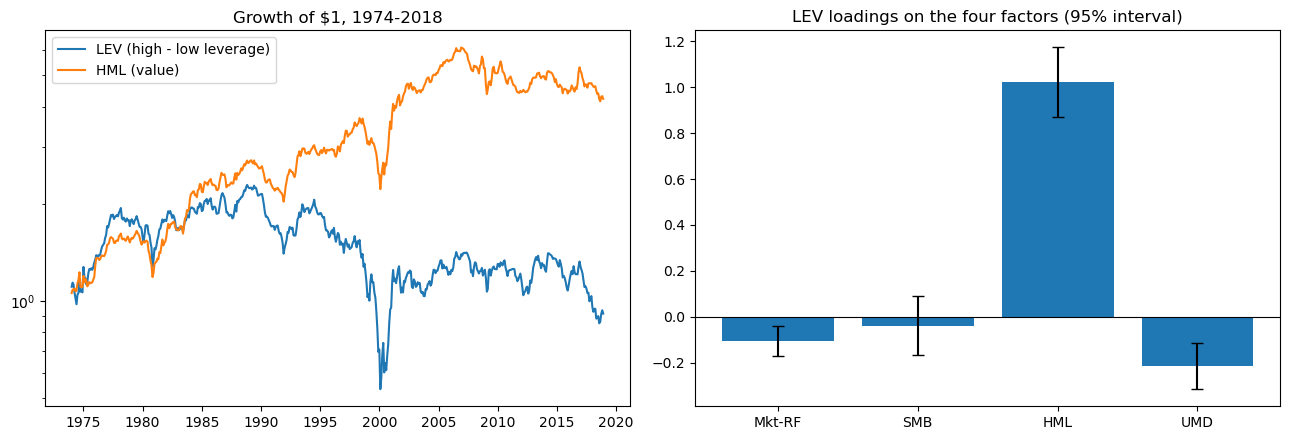

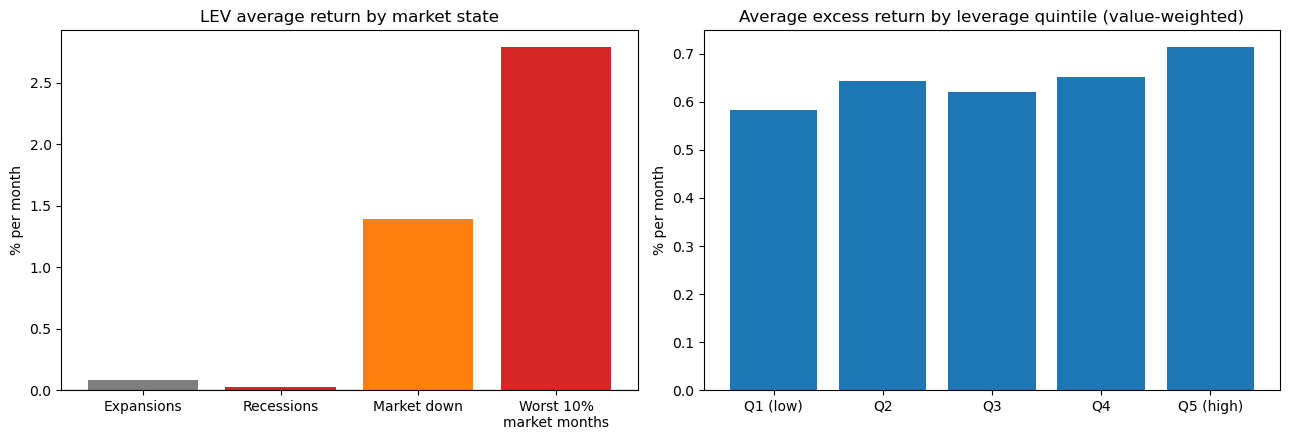

In [17]:
dd = ff.join(lev, how="inner")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for c, label in [("LEV", "LEV (high - low leverage)"), ("HML", "HML (value)")]:
    ax[0].plot(dd.index.to_timestamp(), (1 + dd[c]).cumprod(), label=label)
ax[0].set_yscale("log"); ax[0].set_title("Growth of $1, 1974-2018"); ax[0].legend()
fit = ols(dd["LEV"], dd[FF4])
b = fit[FF4]; ci = 1.96 * abs(b.values / fit[[f"t_{n}" for n in FF4]].values)
ax[1].bar(FF4, b.values, yerr=ci, capsize=4, color="tab:blue")
ax[1].axhline(0, color="black", lw=.8); ax[1].set_title("LEV loadings on the four factors (95% interval)")
fig.tight_layout(); fig.savefig("fig1_lev_vs_hml.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
keys = ["Expansions", "NBER recessions", "Market down (Mkt-RF < 0)", "Worst 10% market months"]
ax[0].bar(["Expansions", "Recessions", "Market down", "Worst 10%\nmarket months"], states.loc[keys, "LEV %"].values,
          color=["tab:gray", "tab:red", "tab:orange", "tab:red"])
ax[0].axhline(0, color="black", lw=.8); ax[0].set_ylabel("% per month"); ax[0].set_title("LEV average return by market state")
quint = port_ret(st, ["lev_q"]).sub(ff["RF"], axis=0).loc[dd.index].mean() * 100
ax[1].bar([f"Q{k+1}" + (" (low)" if k == 0 else " (high)" if k == 4 else "") for k in quint.index], quint.values, color="tab:blue")
ax[1].set_ylabel("% per month"); ax[1].set_title("Average excess return by leverage quintile (value-weighted)")
fig.tight_layout(); fig.savefig("fig2_bad_times_quintiles.png", dpi=200); plt.show()

**What this does:** *Figure 1:* growth of $1 in LEV vs HML (log scale), and LEV's four-factor loadings with 95% intervals. *Figure 2:* LEV's average return in each market state, and the average excess return of the five leverage quintiles. A risk-based factor should show a rising pattern across quintiles and weak payoffs in bad states. Both figures are saved as PNGs.

## 9. Summary of results
**Sample.** 2,006,414 stock-months, 16,801 stocks, 540 months (Jan 1974 - Dec 2018). Returns are winsorized at 1/99 within each month (40,289 returns and 20,335 leverage values changed).

**1. LEV earns no reliable premium.** The average return is **+0.08% per month** (about 0.9% a year), Newey-West t = **0.37**. The low-leverage leg earns 0.97% per month and the high-leverage leg 1.04%.

**2. LEV overlaps heavily with value and is not a new return source.**

| Benchmark | LEV alpha (per month) | t | R-squared of LEV |
|---|---|---|---|
| CAPM | +0.23% | 1.10 | 0.08 |
| FF3 | -0.22% | -1.81 | 0.60 |
| FF3 + UMD | -0.04% | -0.37 | 0.64 |

In the four-factor regression LEV loads **+1.02 on HML (t = 13.2)**, -0.21 on UMD (t = -4.1) and -0.11 on the market (t = -3.2), and is unrelated to SMB. The LEV-HML correlation is 0.77 and HML alone explains 59% of LEV's variation. After the four factors the alpha is zero.

**3. Added explanatory power is real only on leverage-sorted assets.** Adding LEV to a benchmark raises R-squared as follows.

| Benchmark | 25 size x leverage portfolios (partly sorted on leverage): avg R-squared, without -> with LEV | LEV significant | 5 size portfolios (independent of leverage): avg R-squared, without -> with LEV | LEV significant |
|---|---|---|---|---|
| CAPM | 0.631 -> 0.675 (adj. R-squared +0.043) | 17 of 25 | 0.685 -> 0.687 (+0.002) | 0 of 5 |
| FF3 | 0.819 -> 0.834 (+0.015) | 18 of 25 | 0.862 -> 0.864 (+0.002) | 4 of 5 |
| FF3 + UMD | 0.842 -> 0.853 (+0.011) | 18 of 25 | 0.882 -> 0.883 (+0.0001) | 1 of 5 |

On the 25 portfolios the gain is modest (about one point of R-squared over the four-factor model, up to 8 points for the largest, lowest-leverage portfolio). That gain is partly mechanical because the portfolios were sorted on leverage. On the five **independent** size portfolios, LEV adds essentially nothing over the four-factor model (even where it is "significant" under FF3, the R-squared gain is 0.002). In the FF3 + LEV model 14 of the 25 alphas are significant, versus only 3 of 25 once momentum is added (FF4 + LEV), so momentum matters.

**4. Sensitivity: the premium is never significant and added explanatory power stays near zero.** "dR2" is the average gain in R-squared when LEV is added to the four-factor model.

| Specification | Mean %/mo (t) | FF4 alpha %/mo (t) | dR2, 25 ports | dR2, 5 size ports |
|---|---|---|---|---|
| Base (30/70, value-weighted, market leverage) | 0.08 (0.37) | -0.04 (-0.38) | 0.011 | 0.000 |
| Quintiles 20/80 | 0.13 (0.53) | -0.06 (-0.46) | 0.012 | 0.000 |
| Terciles | 0.07 (0.36) | -0.03 (-0.27) | 0.011 | 0.001 |
| Equal-weighted legs | 0.19 (1.00) | +0.08 (0.79) | 0.015 | 0.005 |
| Book leverage | -0.17 (-1.04) | **-0.30 (-2.59)** | 0.010 | 0.000 |
| No winsorizing of returns | 0.08 (0.37) | -0.04 (-0.37) | 0.011 | 0.000 |
| Returns winsorized 5/95 | 0.07 (0.37) | -0.05 (-0.42) | 0.011 | 0.000 |
| 1974-1995 | 0.24 (1.10) | -0.03 (-0.19) | 0.008 | 0.000 |
| 1996-2018 | -0.09 (-0.26) | -0.01 (-0.05) | 0.013 | 0.001 |
| Excluding 2007-09 | 0.08 (0.38) | -0.06 (-0.53) | 0.012 | 0.000 |

The premium changes sign across subperiods and across leverage definitions (book vs market). The one significant number (book leverage, FF4 alpha -0.30%) is one result out of ten specifications and is negative, so it could easily be chance.

**5. Bad times.**

| Market state | Months | Low-leverage leg | High-leverage leg | LEV (%/month) | t |
|---|---|---|---|---|---|
| Expansions | 464 | +1.11 | +1.20 | +0.08 | 0.37 |
| NBER recessions | 76 | +0.09 | +0.11 | +0.02 | 0.06 |
| Market up (Mkt-RF >= 0) | 325 | +4.28 | +3.49 | -0.80 | -3.02 |
| Market down (Mkt-RF < 0) | 215 | -4.04 | -2.65 | **+1.39** | 3.59 |
| Severe decline (Mkt-RF <= -5%) | 52 | -9.53 | -6.66 | +2.86 | 2.22 |

LEV is significantly different between down and up markets (+2.19 percentage points, t = 4.8), but not between recessions and other months (-0.06, t = -0.13). Stress test, one recession at a time (LEV / Mkt-RF / HML, % per month): 1974-75 +1.36 / -1.03 / +1.15; 1980 -0.35 / +1.44 / -0.60; 1981-82 +0.01 / -0.03 / +1.01; 1990-91 -1.03 / +0.37 / -0.64; 2001 -0.63 / -0.93 / +0.91; 2007-09 -0.07 / -2.02 / -0.46. LEV moves with HML in most episodes but has no consistent sign in recessions.

## 10. Rational (risk-based) or behavioral? (requirement 8)
**What a rational, risk-based explanation requires.** A premium that compensates investors for bearing bad-times risk: LEV should earn a positive average return, keep a positive alpha after controlling for known factors, and lose money in bad times.

**What the evidence shows.**
1. *No premium to explain.* The average return is +0.08% per month (t = 0.37) and the four-factor alpha is -0.04% (t = -0.37). There is nothing here for either theory to explain.
2. *The bad-times pattern runs the wrong way for a risk premium.* In down-market months LEV earns **+1.39%** (t = 3.6), and in up-market months **-0.80%** (t = -3.0); its CAPM beta is -0.26. In recessions it earns about nothing (+0.02%, t = 0.06) with no consistent sign across the six episodes. Both legs fall in down markets, but the high-leverage leg falls *less* (-2.65% vs -4.04%). The distress-exposure channel predicts the opposite: highly leveraged stocks should be hit hardest. (Value-weighted, the low-leverage leg is dominated by large high-beta firms, which is why it falls more.)
3. *Overlap with value.* LEV loads +1.02 on HML, so whatever explains the value premium (rational distress risk or behavioral extrapolation, both discussed in class) explains LEV's co-movement as well. Nothing in the data is specific to leverage.

**What a behavioral explanation would predict.** Mispricing of balance-sheet risk should produce a premium concentrated in stocks where arbitrage is hard (small, illiquid firms). Equal weighting, which gives more weight to small firms, raises the point estimate (+0.19% vs +0.08% per month) but it is still insignificant (t = 1.0), and LEV adds nothing for the independent size portfolios.

**Verdict.** Neither account is supported. The evidence is best described as *no leverage-specific premium*: LEV's returns are explained by its value and momentum exposures, and its payoffs in bad times do not resemble compensation for bearing risk.

## 11. Implications for market efficiency (requirement 9)
**Which form of efficiency?** Leverage is built from public accounting data (reported debt) and market prices (market equity), all available to every investor when the portfolio is formed (our timing uses only information released before the return month). The test therefore speaks to **semi-strong** efficiency: can public information be used to earn abnormal returns? Weak-form efficiency concerns past prices only, and strong-form efficiency concerns private information, which this study does not address.

**Does LEV earn a premium?** No. After controlling for market, size, value and momentum the alpha is about zero and is robust across ten specifications. That is **consistent with an efficient market**: investors cannot earn an abnormal return from leverage, and what return pattern exists is explained by exposures to factors that are already known.

**If a premium had appeared** it would be an open question whether it was compensation for bad-times risk or an inefficiency. Our bad-times evidence would have pointed to the latter, since LEV does not lose in bad times.

**Why would a small gross effect not be traded away (Grossman-Stiglitz)?** The largest point estimate, the equal-weighted +0.19% per month (about 2.3% a year, t = 1.0), is not statistically distinguishable from zero. If it were real, it would sit in the small and illiquid stocks where trading and short-selling costs are high and capital is least able to arbitrage, and any gross profit could be consumed by the cost of gathering information and trading. Such a pattern would be consistent with a **near-efficient** market in the Grossman-Stiglitz sense, in which prices are efficient up to the cost of information. This study measures gross returns only, so that cost argument is untested.

## 12. Conclusion, implications for the audience, and limitations
**Conclusion.** Market leverage is not a separately priced factor in US stocks from 1974 to 2018. High-minus-low leverage earns no reliable average return, its returns are explained by value (and, negatively, momentum and the market), it adds essentially no explanatory power for assets not sorted on leverage, and it does not lose consistently in bad times.

**For quantitative managers and pension funds.** A leverage tilt would overlap heavily with a value tilt they probably already hold, add no return and no reliable bad-times protection, and the sign of its premium changes across periods. Before costs there is nothing to earn, so after costs there is no reason to add it as a separate factor. Its apparent payoff in down markets reflects a negative market beta (-0.26), which can be obtained more directly by reducing market exposure.

**Limitations.**
1. Compustat debt is not comparable across 2019 (the zero-debt share falls from about 19% to 6%, apparently because lease liabilities were added to reported debt), so the sample ends in 2018 and does not cover 2019-2025.
2. Leverage uses current market equity, so it partly proxies for past returns (value and momentum). Annual-data studies that lag leverage would differ.
3. The 25 size x leverage portfolios are partly sorted on leverage, which flatters LEV's explanatory power; the five independent size portfolios are a cleaner but smaller test.
4. Breakpoints use all listed stocks, not NYSE stocks only; the baseline is value-weighted (the equal-weighted version is in the sensitivity table).
5. Ten specifications were examined, so one significant result (book leverage) is weak evidence. No separate out-of-sample period was reserved.
6. Returns are gross of trading, borrowing and financing costs.
7. We believe CRSP's `MthRet` includes delisting returns (last-month returns show an excess of large losses), but we did not verify this against CRSP documentation.
8. Financial firms are excluded, so the results do not apply to banks and insurers.

## 13. Requirements checklist and reproducibility
| # | Requirement | Where |
|---|---|---|
| 1 | Rationale (bad times), audience | Section 1 |
| 2 | Factor time series and test assets from CRSP/Compustat | Sections 2-3 (LEV); Section 5b (25 size x leverage and 5 size test portfolios) |
| 3 | Total returns, variable, frequency | Section 2 (`MthRet`, monthly; includes dividends, split-adjusted) |
| 4 | Missing values, duplicates, outliers, winsorizing with cut-offs, observation counts | Section 2 step logs; Section 3 winsorizing (1/99) and audit table |
| 5 | OLS of test assets on the factor and market: loadings, t-statistics, R-squared | Section 5b (per asset, both test-asset sets) |
| 6 | Explanatory power vs a benchmark model | Section 5a (LEV vs CAPM/FF3/FF4), Section 5b (R-squared and adjusted R-squared with and without LEV) |
| 7 | Sensitivity to assumptions (at least two) | Section 6 (ten specifications: construction, winsorizing, sub-periods, crisis exclusion) |
| 8 | Rational vs behavioral, with bad-times evidence | Sections 7 and 10 |
| 9 | Market efficiency, audience implications | Sections 11 and 12 |

**Reproducibility.** Inputs: `compustat.csv.gz`, `crsp_monthly.csv.gz` (raw WRDS extracts) and `04_Fama_French_Monthly_Factors.csv`, all in this folder. Run the notebook top to bottom; it regenerates `stock_timed.csv` and `permnos.txt` and saves the two figures. It needs only `pandas`, `numpy` and `matplotlib`, and was checked on pandas 1.5 and pandas 3.1. The regression function was verified against `statsmodels` HAC regressions (agreement to 1e-14).